# 03 — Analysis: what the commission really costs

We now have a clean table of **1,084 funds**, each with the measured annual return
gap between its Regular and Direct plan. This notebook answers four questions:

1. **How big is the hidden fee?**
2. **Where does it bite hardest** (by category and fund house)?
3. **Is it a flat toll, or does it depend on performance?**
4. **What does it cost a real investor** over a working life?

Every chart is read in plain words underneath it.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import cleaning, plotting, paths
plotting.set_style()

df = pd.read_csv(paths.RETURNS_CSV)
print(f"{len(df):,} funds | "
      f"{df.fund_house.nunique()} houses | windows up to {df.window_years.max():.1f} years")
df.head(3)

1,084 funds | 50 houses | windows up to 13.4 years


,fund_name,fund_house,broad_category,scheme_category,direct_code,regular_code,window_start,window_end,window_years,direct_cagr,regular_cagr,drag_pp,drag_pp_winsor,is_outlier_flag
0,Principal Small Cap Fund,Principal Mutual Fund,Equity,Equity Scheme - Small Cap Fund,147131,147129,2019-05-14,2021-12-30,2.63,0.435458,0.410290,2.516718,2.185423,False
1,Sundaram Equity Fund,Sundaram Mutual Fund,Equity,Equity Scheme - Multi Cap Fund,147587,147584,2019-09-11,2021-12-31,2.31,0.268327,0.245050,2.327687,2.185423,False
2,ITI Mid Cap Fund,ITI Mutual Fund,Equity,Equity Scheme - Mid Cap Fund,148733,148732,2021-03-10,2026-06-05,5.24,0.185532,0.162665,2.286648,2.185423,False


## Q1 — How big is the hidden fee?

`drag_pp` is how many percentage points *more* per year the Direct plan earned —
i.e. the annual commission the Regular investor handed over. We lead with the
**median** (robust to the data-artefact tails discussed in nb 02).

Median drag, ALL funds   : 0.81 pp/yr
Median drag, EQUITY funds: 1.44 pp/yr
Share of funds where Direct beat Regular: 99.0%


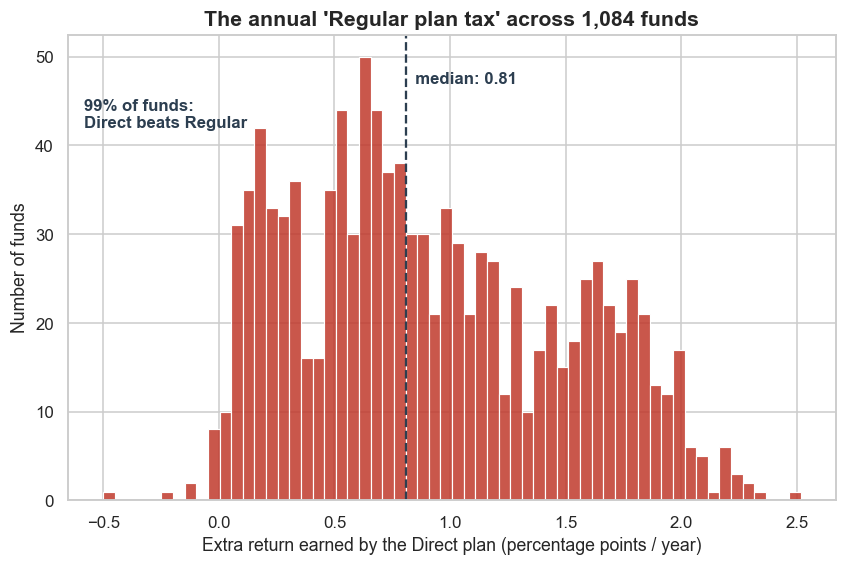

In [2]:
overall_med = df["drag_pp"].median()
eq = df[df.broad_category == "Equity"]
eq_med = eq["drag_pp"].median()
print(f"Median drag, ALL funds   : {overall_med:.2f} pp/yr")
print(f"Median drag, EQUITY funds: {eq_med:.2f} pp/yr")
print(f"Share of funds where Direct beat Regular: {(df.drag_pp > 0).mean()*100:.1f}%")

fig, ax = plt.subplots()
sns.histplot(df["drag_pp"].clip(-0.5, 3.0), bins=60, ax=ax,
             color=plotting.PALETTE["regular"], alpha=0.85)
ax.set_title("The annual 'Regular plan tax' across 1,084 funds")
ax.set_xlabel("Extra return earned by the Direct plan (percentage points / year)")
ax.set_ylabel("Number of funds")
plotting.annotate_median(ax, df["drag_pp"], label="median", orient="v")
ax.text(0.02, 0.80, f"{(df.drag_pp>0).mean()*100:.0f}% of funds:\nDirect beats Regular",
        transform=ax.transAxes, color=plotting.PALETTE["accent"], fontweight="bold")
plotting.save_fig(fig, "03_drag_distribution")
plt.show()

**Reading it.** The distribution sits almost entirely to the right of zero: in the
overwhelming majority of funds the Direct plan wins, exactly as the identical-portfolio
logic predicts. The typical fund quietly charges its Regular investors around
**0.8 percentage points a year overall — and ~1.4 pp/yr for equity funds** — for
nothing but the act of having been sold to them. That sounds tiny. Compounded over
decades, it is not — see Q4.

*(The handful of funds left of zero are the NAV-artefact outliers from nb 02, not
real cases of commissions creating value.)*

## Q2 — Where does it bite hardest?

Commissions are capped higher on equity funds than on debt funds, so we expect
equity investors to lose the most. We check by **broad category**, then name the
**fund houses** with the steepest equity drag.

                median  mean    n
broad_category                   
Equity            1.44  1.42  367
Hybrid            1.29  1.23  148
Other/Index       0.51  0.43  311
Debt              0.49  0.49  258


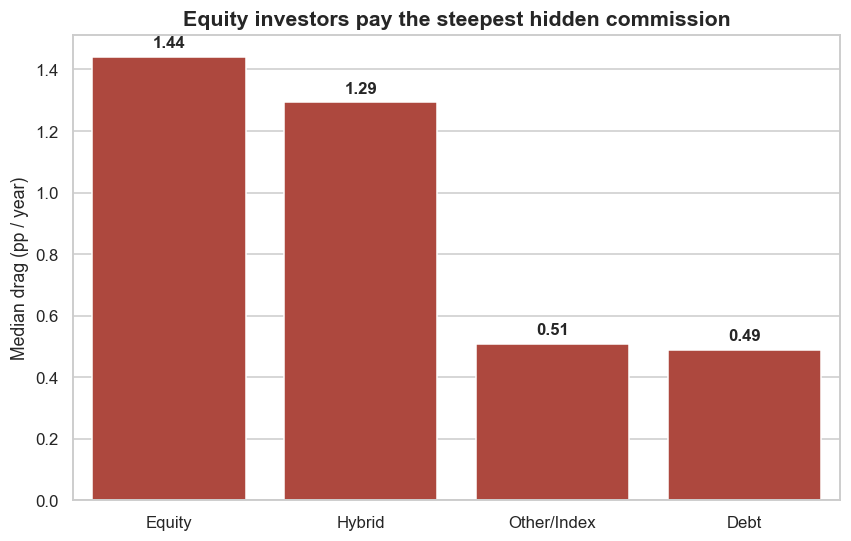

In [3]:
cat_stats = (df.groupby("broad_category")["drag_pp"]
             .agg(median="median", mean="mean", n="count")
             .sort_values("median", ascending=False))
print(cat_stats.round(2))

order = cat_stats.index.tolist()
fig, ax = plt.subplots()
sns.barplot(data=df, x="broad_category", y="drag_pp", order=order,
            estimator=np.median, errorbar=None, color=plotting.PALETTE["regular"], ax=ax)
for i, c in enumerate(order):
    m = cat_stats.loc[c, "median"]
    ax.text(i, m + 0.03, f"{m:.2f}", ha="center", fontweight="bold")
ax.set_title("Equity investors pay the steepest hidden commission")
ax.set_xlabel(""); ax.set_ylabel("Median drag (pp / year)")
plotting.save_fig(fig, "03_drag_by_category")
plt.show()

**Reading it.** The penalty scales exactly the way commission economics predict:
**equity funds carry the highest drag**, hybrids next, then debt and index/other.
Equity is also where Indians park most of their long-horizon money — so the costliest
plans sit precisely where the compounding horizon is longest. The worst of both worlds.

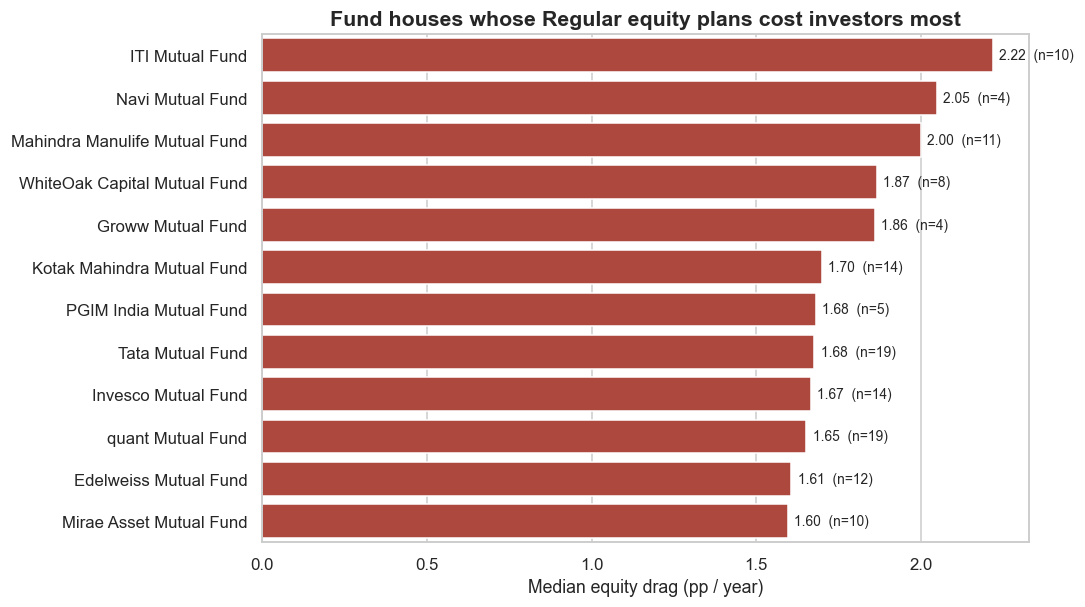

(Houses with >=4 equity funds in the sample)


In [4]:
# Fund houses with the steepest EQUITY drag (>=4 equity funds, for a fair median).
house = (eq.groupby("fund_house")["drag_pp"]
         .agg(median="median", n="count"))
house = house[house["n"] >= 4].sort_values("median", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=house["median"], y=house.index, color=plotting.PALETTE["regular"], ax=ax)
for i, (m, n) in enumerate(zip(house["median"], house["n"])):
    ax.text(m + 0.02, i, f"{m:.2f}  (n={n})", va="center", fontsize=9)
ax.set_title("Fund houses whose Regular equity plans cost investors most")
ax.set_xlabel("Median equity drag (pp / year)"); ax.set_ylabel("")
plotting.save_fig(fig, "03_top_houses")
plt.show()
print("(Houses with >=4 equity funds in the sample)")

**Reading it.** Among large houses the median equity drag clusters around
**1.0–1.5 pp/yr**, with several pushing past that. This isn't about one rogue
fund company — it's a structural feature of how Regular plans are priced across
the whole industry.

## Q3 — A flat toll, or performance-linked?

A fair question a sceptic would ask: *maybe the gap is just noise that happens to
correlate with how the fund did.* If the drag were really the commission, it should
be **roughly constant regardless of the fund's return** — a flat toll, not a share
of the winnings. We test that for equity funds.

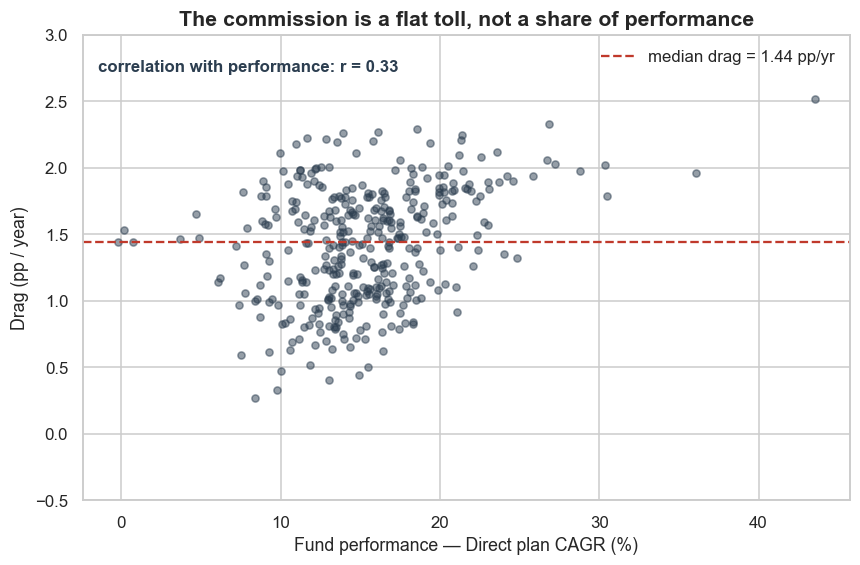

In [5]:
corr = eq["direct_cagr"].corr(eq["drag_pp"])
fig, ax = plt.subplots()
ax.scatter(eq["direct_cagr"] * 100, eq["drag_pp"], s=22, alpha=0.5,
           color=plotting.PALETTE["accent"])
ax.axhline(eq_med, color=plotting.PALETTE["regular"], ls="--", lw=1.5,
           label=f"median drag = {eq_med:.2f} pp/yr")
ax.set_title("The commission is a flat toll, not a share of performance")
ax.set_xlabel("Fund performance — Direct plan CAGR (%)")
ax.set_ylabel("Drag (pp / year)")
ax.set_ylim(-0.5, 3.0)
ax.legend()
ax.text(0.02, 0.92, f"correlation with performance: r = {corr:.2f}",
        transform=ax.transAxes, fontweight="bold", color=plotting.PALETTE["accent"])
plotting.save_fig(fig, "03_flat_toll_scatter")
plt.show()

**Reading it.** The cloud is flat — the drag barely moves with how well the fund
performs (correlation near zero). Good funds and mediocre funds charge Regular
investors about the same toll. That's the signature of a **fixed annual fee**, which
is exactly what a distributor commission is. It confirms we're measuring the cost
structure, not some performance artefact.

## Q4 — What does it cost a real person?

A percentage point sounds ignorable. Let's translate it into rupees for a realistic
saver: a **₹10,000/month SIP** in a typical equity fund, held for a working life.
We grow the Direct plan at the median equity Direct return, and the Regular plan at
that return *minus* the median drag — then read off the gap.

In [6]:
monthly = 10_000
gross = eq["direct_cagr"].median()           # typical equity Direct return
drag = eq_med                                # median equity drag (pp/yr)
print(f"Assumptions: ₹{monthly:,}/month SIP | Direct return {gross*100:.1f}%/yr | "
      f"drag {drag:.2f} pp/yr\n")

rows = []
for yrs in [10, 15, 20, 25, 30]:
    r = cleaning.sip_drag_cost(monthly, gross, drag, yrs)
    rows.append({"years": yrs, "invested": r["invested"],
                 "direct_corpus": r["direct_fv"], "regular_corpus": r["regular_fv"],
                 "lost_to_commission": r["lost_to_drag"],
                 "pct_of_corpus_lost": r["lost_pct_of_corpus"]})
sip = pd.DataFrame(rows)
fmt = sip.copy()
for c in ["invested","direct_corpus","regular_corpus","lost_to_commission"]:
    fmt[c] = fmt[c].map(lambda x: f"₹{x/1e5:,.1f} L")
fmt["pct_of_corpus_lost"] = fmt["pct_of_corpus_lost"].map(lambda x: f"{x:.1f}%")
fmt

Assumptions: ₹10,000/month SIP | Direct return 14.9%/yr | drag 1.44 pp/yr



,years,invested,direct_corpus,regular_corpus,lost_to_commission,pct_of_corpus_lost
0,10,₹12.0 L,₹27.6 L,₹25.3 L,₹2.3 L,8.4%
1,15,₹18.0 L,₹66.8 L,₹57.9 L,₹8.9 L,13.3%
2,20,₹24.0 L,₹148.8 L,₹121.5 L,₹27.3 L,18.3%
3,25,₹30.0 L,₹320.5 L,₹245.6 L,₹74.9 L,23.4%
4,30,₹36.0 L,₹680.0 L,₹487.4 L,₹192.6 L,28.3%


/Users/shauryakesarwani/Desktop/prjcts/data-analysis-mutual-fund-fees/src/plotting.py:44: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from current font.
  fig.savefig(paths.FIGURES / f"{name}.png")
/Users/shauryakesarwani/Desktop/prjcts/data-analysis-mutual-fund-fees/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


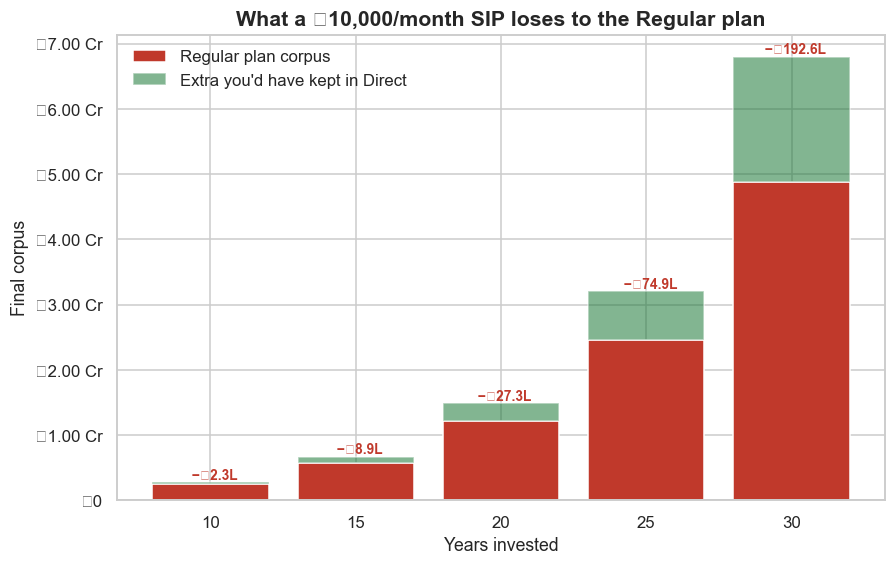

In [7]:
fig, ax = plt.subplots()
x = sip["years"].astype(str)
ax.bar(x, sip["regular_corpus"], color=plotting.PALETTE["regular"], label="Regular plan corpus")
ax.bar(x, sip["lost_to_commission"], bottom=sip["regular_corpus"],
       color=plotting.PALETTE["direct"], alpha=0.55, label="Extra you'd have kept in Direct")
ax.yaxis.set_major_formatter(plotting.rupee_formatter())
ax.set_title("What a ₹10,000/month SIP loses to the Regular plan")
ax.set_xlabel("Years invested"); ax.set_ylabel("Final corpus")
ax.legend(loc="upper left")
for i, row in sip.iterrows():
    ax.text(i, row["direct_corpus"], f"  −₹{row['lost_to_commission']/1e5:.1f}L",
            ha="center", va="bottom", fontsize=9, fontweight="bold",
            color=plotting.PALETTE["regular"])
plotting.save_fig(fig, "03_sip_lifetime_cost")
plt.show()

In [8]:
row30 = sip[sip.years == 30].iloc[0]
row20 = sip[sip.years == 20].iloc[0]
print(f"Over 20 years, the Regular investor loses ₹{row20.lost_to_commission/1e5:.1f} lakh "
      f"({row20.pct_of_corpus_lost:.0f}% of what they'd have had).")
print(f"Over 30 years, the gap balloons to ₹{row30.lost_to_commission/1e5:.1f} lakh "
      f"({row30.pct_of_corpus_lost:.0f}% of the corpus) — on just ₹10k/month.")

Over 20 years, the Regular investor loses ₹27.3 lakh (18% of what they'd have had).
Over 30 years, the gap balloons to ₹192.6 lakh (28% of the corpus) — on just ₹10k/month.


## Findings & takeaways (in plain English)

**The one-line story:** Buying the "Regular" version of a mutual fund — the default
when you invest through most banks, agents and apps — costs the typical equity
investor **more than a quarter (~28%) of their final wealth** across a 30-year
savings life, for a product that is otherwise *identical* to the free "Direct" version.

What we found:

1. **It's real and near-universal.** In **99% of funds** the Direct plan beats the
   Regular plan, and the typical equity fund skims about **1.4 percentage points a
   year** off Regular investors.
2. **It's worst where it hurts most.** Equity funds — where people invest for the
   long haul — carry the steepest drag, so the cost compounds over the longest horizon.
3. **It's a flat toll.** The commission doesn't reward good performance; it's a fixed
   annual leak that good and bad funds charge alike.
4. **The rupee cost is life-changing.** On a modest ₹10,000/month SIP, the Regular
   plan quietly costs **tens of lakhs** over a working life — money that stays in
   *your* pocket simply by choosing the Direct plan of the same fund.

**The fix costs nothing.** Every Regular plan has a Direct twin with a lower expense
ratio and an identical portfolio. Switching (or starting Direct) is the rare
financial decision that is pure upside.

**Next:** `04_modeling` confirms the gap is statistically real (paired test) and
models which fund characteristics predict its size.